# Bharatanatyam Mudra Recognition — Exit Examination
**End-to-end image classification with a custom CNN, error analysis, transfer learning, and Streamlit deployment**



In [1]:

from google.colab import files
uploaded = files.upload()
ZIP_PATH = next((name for name in uploaded if name.lower().endswith(".zip")), None)
if ZIP_PATH is None:
    raise FileNotFoundError("Please upload the dataset ZIP file (mudra.zip).")
print("Using:", ZIP_PATH)

Saving mudra.zip to mudra (1).zip
Using: mudra (1).zip


In [2]:
import os, zipfile, random, time, json, shutil, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
DATA_DIR = Path("/content/mudra_dataset")
DATA_DIR.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    zf.extractall(DATA_DIR)
print("Extracted to:", DATA_DIR)
print("Top-level entries:", [p.name for p in list(DATA_DIR.iterdir())[:20]])

Extracted to: /content/mudra_dataset
Top-level entries: ['Bharatanatyam_Mudras']


## Task 1 — Dataset analysis



In [3]:
CLASS_FOLDER_NAMES_TO_IGNORE = {
    "train", "training", "test", "testing", "val", "valid", "validation",
    "images", "image", "dataset", "data", "mudra", "mudra_dataset"
}
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

all_image_paths = [p for p in DATA_DIR.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTS]
if not all_image_paths:
    raise RuntimeError("No image files found. Check the ZIP extraction and folder structure.")

records = []
for p in all_image_paths:

    class_name = p.parent.name
    if class_name.lower() in CLASS_FOLDER_NAMES_TO_IGNORE:

        candidates = [part for part in p.parts if part.lower() not in CLASS_FOLDER_NAMES_TO_IGNORE]
        class_name = p.parent.parent.name if p.parent.parent != DATA_DIR.parent else class_name
        if class_name.lower() in CLASS_FOLDER_NAMES_TO_IGNORE:
            continue
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            width, height = im.size
            mode = im.mode
        records.append({"path": str(p), "label": class_name, "width": width, "height": height,
                        "mode": mode, "file_size_kb": round(p.stat().st_size / 1024, 2)})
    except Exception as e:
        print("Skipping unreadable image:", p, "|", str(e)[:100])

df = pd.DataFrame(records)
if df.empty:
    raise RuntimeError("No valid class-labelled images were found. Inspect the folders and update class-label inference.")
print("Total valid images:", len(df))
print("Detected classes:", sorted(df.label.unique()))
display(df.head())
print("Image dimensions summary:")
display(df[["width","height","file_size_kb"]].describe().round(2))

Total valid images: 2000
Detected classes: ['Musti', 'Pataka', 'Sikhara', 'Simhamukha', 'Trisula']


,path,label,width,height,mode,file_size_kb
0,/content/mudra_dataset/Bharatanatyam_Mudras/Mu...,Musti,300,300,RGB,25.72
1,/content/mudra_dataset/Bharatanatyam_Mudras/Mu...,Musti,300,300,RGB,26.68
2,/content/mudra_dataset/Bharatanatyam_Mudras/Mu...,Musti,300,300,RGB,27.60
3,/content/mudra_dataset/Bharatanatyam_Mudras/Mu...,Musti,300,300,RGB,28.42
4,/content/mudra_dataset/Bharatanatyam_Mudras/Mu...,Musti,300,300,RGB,29.74


Image dimensions summary:


,width,height,file_size_kb
count,2000.0,2000.0,2000.00
mean,300.0,300.0,28.08
std,0.0,0.0,1.50
min,300.0,300.0,24.23
25%,300.0,300.0,26.96
50%,300.0,300.0,28.10
75%,300.0,300.0,29.31
max,300.0,300.0,31.36


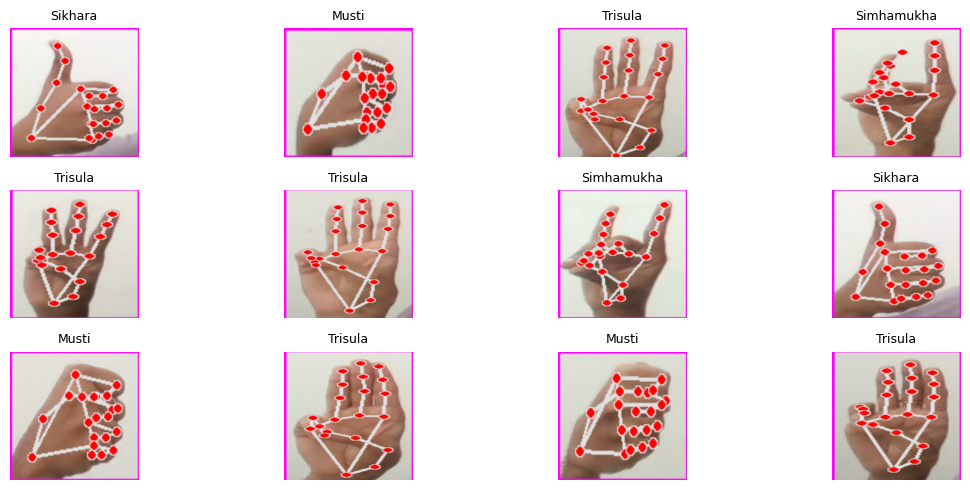

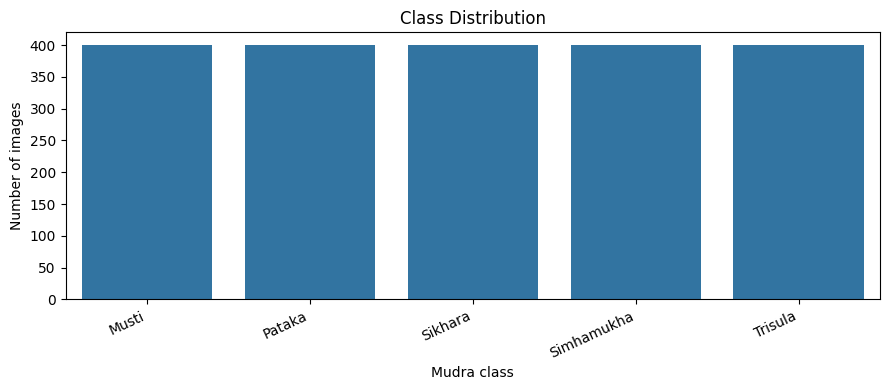

,missing_count
path,0
label,0
width,0
height,0
mode,0
file_size_kb,0


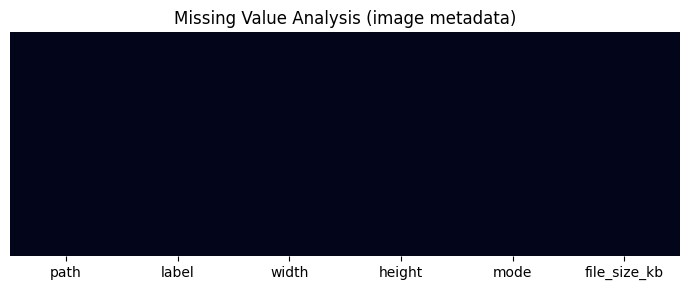

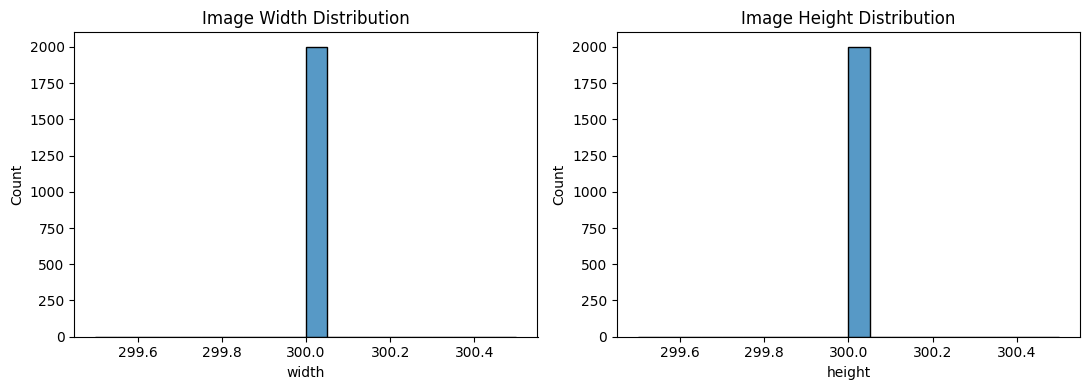

Class counts:


,image_count
label,
Musti,400
Pataka,400
Sikhara,400
Simhamukha,400
Trisula,400


Class balance ratio (largest/smallest): 1.0
All plots saved successfully in the screenshots folder.


In [6]:

import os
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image


os.makedirs("screenshots", exist_ok=True)


plt.figure(figsize=(12, 5))
sample_df = df.sample(min(12, len(df)), random_state=SEED)

for i, (_, row) in enumerate(sample_df.iterrows(), 1):
    plt.subplot(3, 4, i)
    img = Image.open(row["path"]).convert("RGB")
    plt.imshow(img)
    plt.title(row["label"], fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.savefig("screenshots/dataset_preview.png",
            dpi=150, bbox_inches="tight")
plt.show()

class_counts = df["label"].value_counts().sort_index()

plt.figure(figsize=(9, 4))
sns.barplot(x=class_counts.index, y=class_counts.values)
plt.title("Class Distribution")
plt.xlabel("Mudra class")
plt.ylabel("Number of images")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig("screenshots/class_distribution.png",
            dpi=150, bbox_inches="tight")
plt.show()


missing = df.isna().sum().rename("missing_count").to_frame()
display(missing)

plt.figure(figsize=(7, 3))
sns.heatmap(df.isna(), cbar=False, yticklabels=False)
plt.title("Missing Value Analysis (image metadata)")
plt.tight_layout()
plt.savefig("screenshots/missing_value_analysis.png",
            dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.histplot(df["width"], bins=20, ax=axes[0])
axes[0].set_title("Image Width Distribution")

sns.histplot(df["height"], bins=20, ax=axes[1])
axes[1].set_title("Image Height Distribution")

plt.tight_layout()
plt.savefig("screenshots/image_characteristics.png",
            dpi=150, bbox_inches="tight")
plt.show()


print("Class counts:")
display(class_counts.to_frame("image_count"))


print(
    "Class balance ratio (largest/smallest):",
    round(class_counts.max() / class_counts.min(), 2)
)

print("All plots saved successfully in the screenshots folder.")


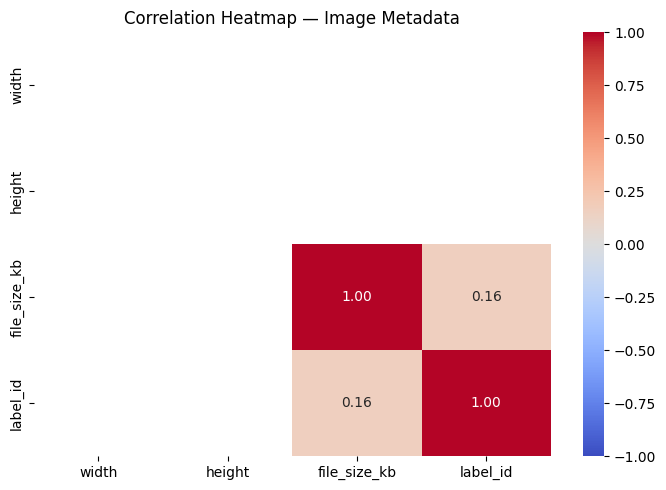

In [7]:
numeric_metadata = df[["width", "height", "file_size_kb"]].copy()
numeric_metadata["label_id"] = df["label_id"] if "label_id" in df.columns else df["label"].astype("category").cat.codes
plt.figure(figsize=(7, 5))
sns.heatmap(numeric_metadata.corr(numeric_only=True), annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation Heatmap — Image Metadata")
plt.tight_layout()
plt.savefig("screenshots/correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

### Analytical answers — Task 1
1. **Is the dataset balanced?** Each class represents 20% of the dataset, and the largest-to-smallest class ratio is \(400/400 = 1.0\). Therefore, there is no class imbalance, and the model is not biased toward any class due to differences in image counts.
2. **What makes recognition difficult?** Similar finger arrangements, different camera angles, hand rotation, occlusion, jewellery/sleeves, shadows, busy backgrounds, different skin tones, blur, and variation in distance/scale can make classes hard to separate.
3. **Does higher resolution always help?** No. Higher resolution can preserve finger details, but it increases memory and compute cost and may add little value if source images are blurry or the model is small. Compare resolutions experimentally and keep the same split when comparing.

## Create stratified train / validation / test splits

We use a 70/15/15 split and stratify by class so each split preserves class proportions. If any class has too few images to stratify, the code reports the issue and uses a non-stratified fallback.

In [8]:
from sklearn.model_selection import train_test_split
labels = sorted(df["label"].unique())
label_to_id = {label: i for i, label in enumerate(labels)}
id_to_label = {i: label for label, i in label_to_id.items()}
df["label_id"] = df["label"].map(label_to_id)

try:
    train_df, temp_df = train_test_split(df, test_size=0.30, random_state=SEED, stratify=df["label_id"])
    val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=SEED, stratify=temp_df["label_id"])
except ValueError as e:
    print("Stratified split unavailable:", e)
    train_df, temp_df = train_test_split(df, test_size=0.30, random_state=SEED)
    val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=SEED)

for name, part in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    print(f"{name}: {len(part)} images")
    display(part["label"].value_counts().reindex(labels, fill_value=0).rename(name).to_frame())

Train: 1400 images


,Train
label,
Musti,280
Pataka,280
Sikhara,280
Simhamukha,280
Trisula,280


Validation: 300 images


,Validation
label,
Musti,60
Pataka,60
Sikhara,60
Simhamukha,60
Trisula,60


Test: 300 images


,Test
label,
Musti,60
Pataka,60
Sikhara,60
Simhamukha,60
Trisula,60


## Task 2 — Preprocessing and augmentation

Images are resized to 160×160 and converted to RGB. The model receives float pixels scaled to [0, 1]. Augmentation is applied **only to training data**. Horizontal flipping is included as a configurable option; disable it if the dataset or a mudra's handedness makes left/right orientation semantically important.

TensorFlow: 2.21.0


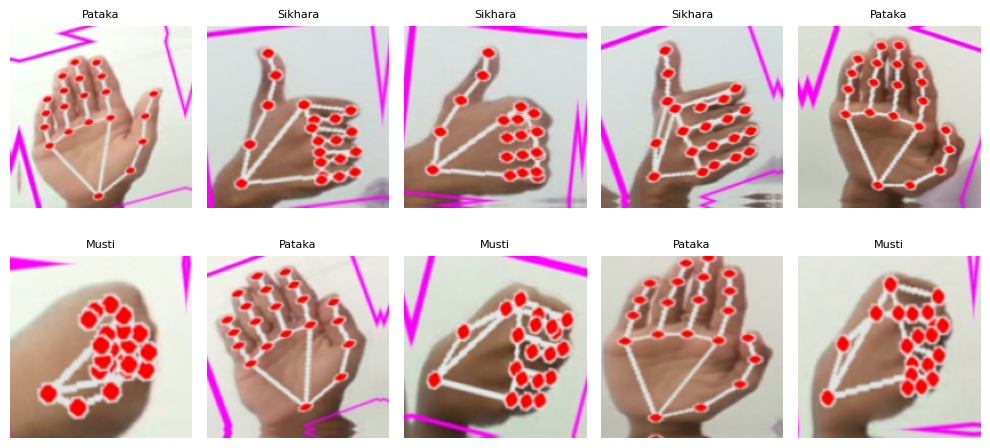

In [9]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
print("TensorFlow:", tf.__version__)
IMG_SIZE = (160, 160)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE
NUM_CLASSES = len(labels)

def load_image(path, label_id):
    raw = tf.io.read_file(path)
    image = tf.image.decode_image(raw, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, tf.cast(label_id, tf.int32)

def make_dataset(frame, training=False):
    paths = frame["path"].astype(str).values
    y = frame["label_id"].astype("int32").values
    ds = tf.data.Dataset.from_tensor_slices((paths, y))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

augmentation = keras.Sequential([
    layers.RandomRotation(0.06),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.06, 0.06),
    layers.RandomContrast(0.10),
], name="augmentation")
# Optional: enable only if reflection preserves the label for your dataset.
USE_HORIZONTAL_FLIP = False
if USE_HORIZONTAL_FLIP:
    augmentation = keras.Sequential([layers.RandomFlip("horizontal"), *augmentation.layers], name="augmentation")

# Visualize augmented examples
for images, batch_labels in train_ds.take(1):
    aug_images = augmentation(images, training=True)
    plt.figure(figsize=(10, 5))
    for i in range(min(10, len(images))):
        plt.subplot(2, 5, i+1)
        plt.imshow(tf.clip_by_value(aug_images[i], 0, 1).numpy())
        plt.title(id_to_label[int(batch_labels[i])], fontsize=8)
        plt.axis("off")
    plt.tight_layout()
    plt.savefig("screenshots/augmented_samples.png", dpi=150, bbox_inches="tight")
    plt.show()

### Analytical answers — Task 2
1. **Meaning-preserving augmentation:** small rotations, modest translations/zoom, and mild brightness/contrast changes can represent realistic camera variation. Avoid transformations that change the gesture itself. Horizontal flips should be used only if mirrored gestures are still valid labels in this dataset.
2. **Potentially harmful augmentation:** large rotations/crops can cut off fingers; strong blur/noise can erase finger details; aggressive colour shifts can distort useful visual cues; vertical flips and extreme perspective warps can create unrealistic hands. Augmentations should match real practice-session conditions.

## Task 3 — Custom CNN development and hyperparameter tuning

We compare at least two hyperparameter settings: learning rate and dropout. To keep the examination run manageable, each configuration uses early stopping. Training curves are saved for the final custom CNN.

In [12]:

def build_custom_cnn(learning_rate=1e-3, dropout_rate=0.3):
    inputs = keras.Input(shape=(*IMG_SIZE, 3))
    x = augmentation(inputs)

    for filters in [16, 32]:
        x = layers.Conv2D(
            filters, 3, padding="same", activation="relu"
        )(x)
        x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout_rate)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    model = keras.Model(inputs, outputs, name="lightweight_mudra_cnn")

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


model = build_custom_cnn()

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    )
]

start = time.time()

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=callbacks,
    class_weight=class_weight,
    verbose=1
)

print("Training time:", round(time.time() - start, 1), "seconds")


Epoch 1/5
44/44 ━━━━━━━━━━━━━━━━━━━━ 59s 1s/step - accuracy: 0.2307 - loss: 1.6051 - val_accuracy: 0.3567 - val_loss: 1.5848
Epoch 2/5
44/44 ━━━━━━━━━━━━━━━━━━━━ 47s 1s/step - accuracy: 0.2829 - loss: 1.5442 - val_accuracy: 0.3600 - val_loss: 1.4582
Epoch 3/5
44/44 ━━━━━━━━━━━━━━━━━━━━ 78s 983ms/step - accuracy: 0.3979 - loss: 1.4006 - val_accuracy: 0.4567 - val_loss: 1.2521
Epoch 4/5
44/44 ━━━━━━━━━━━━━━━━━━━━ 44s 993ms/step - accuracy: 0.4850 - loss: 1.2475 - val_accuracy: 0.5367 - val_loss: 1.2109
Epoch 5/5
44/44 ━━━━━━━━━━━━━━━━━━━━ 84s 1s/step - accuracy: 0.5150 - loss: 1.1377 - val_accuracy: 0.5500 - val_loss: 1.0324
Training time: 311.7 seconds


Selected learning rate: 0.001
Selected dropout: 0.3
Epoch 1/5
44/44 ━━━━━━━━━━━━━━━━━━━━ 51s 1s/step - accuracy: 0.1929 - loss: 1.6116 - val_accuracy: 0.3300 - val_loss: 1.6065
Epoch 2/5
44/44 ━━━━━━━━━━━━━━━━━━━━ 101s 2s/step - accuracy: 0.2214 - loss: 1.5963 - val_accuracy: 0.2567 - val_loss: 1.5717
Epoch 3/5
44/44 ━━━━━━━━━━━━━━━━━━━━ 64s 1s/step - accuracy: 0.3079 - loss: 1.5265 - val_accuracy: 0.3000 - val_loss: 1.4660
Epoch 4/5
44/44 ━━━━━━━━━━━━━━━━━━━━ 50s 1s/step - accuracy: 0.4086 - loss: 1.3927 - val_accuracy: 0.4600 - val_loss: 1.2826
Epoch 5/5
44/44 ━━━━━━━━━━━━━━━━━━━━ 43s 969ms/step - accuracy: 0.4471 - loss: 1.2658 - val_accuracy: 0.4367 - val_loss: 1.2457
Training time: 347.9 seconds


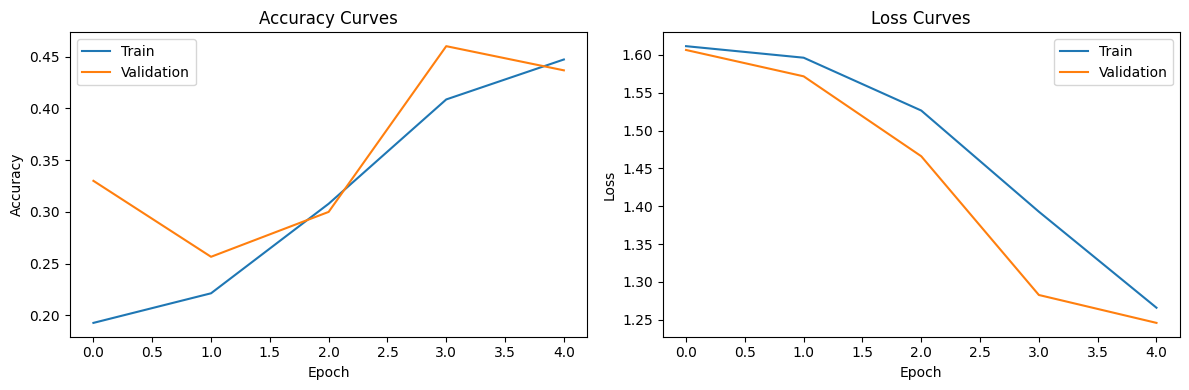

In [14]:

import os
import time
import matplotlib.pyplot as plt

os.makedirs("screenshots", exist_ok=True)


BEST_LR = 1e-3
BEST_DROPOUT = 0.3

print("Selected learning rate:", BEST_LR)
print("Selected dropout:", BEST_DROPOUT)


custom_model = build_custom_cnn(
    learning_rate=BEST_LR,
    dropout_rate=BEST_DROPOUT
)

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    )
]

start = time.time()

custom_history = custom_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=callbacks,
    class_weight=class_weight,
    verbose=1
)

custom_train_seconds = time.time() - start

print("Training time:", round(custom_train_seconds, 1), "seconds")


fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(custom_history.history["accuracy"], label="Train")
axes[0].plot(custom_history.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy Curves")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(custom_history.history["loss"], label="Train")
axes[1].plot(custom_history.history["val_loss"], label="Validation")
axes[1].set_title("Loss Curves")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.savefig(
    "screenshots/training_validation_curves.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()


### Analytical answers — Task 3
1. **Hyperparameters:** learning rate controls the size of optimizer updates. A high rate can learn quickly but overshoot a good solution; a lower rate is steadier but may need more epochs. Dropout randomly disables some activations during training and can reduce overfitting; too much dropout can slow learning or cause underfitting. The tuning table shows which combination performed best on validation accuracy.
2. **Underfitting or overfitting:** compare training and validation curves. If both accuracies remain low, the model may underfit. If training accuracy keeps rising while validation accuracy stalls/falls, or training loss falls while validation loss rises, the model is overfitting. Use the plotted curves to state what happened in this run rather than assuming either outcome.

## Task 4 — Evaluation and failure analysis



,Metric,Score
0,Accuracy,0.4367
1,Precision (macro),0.4347
2,Recall (macro),0.4367
3,F1-score (macro),0.3862


              precision    recall  f1-score   support

       Musti       1.00      0.62      0.76        60
      Pataka       0.44      1.00      0.61        60
     Sikhara       0.00      0.00      0.00        60
  Simhamukha       0.21      0.37      0.27        60
     Trisula       0.52      0.20      0.29        60

    accuracy                           0.44       300
   macro avg       0.43      0.44      0.39       300
weighted avg       0.43      0.44      0.39       300



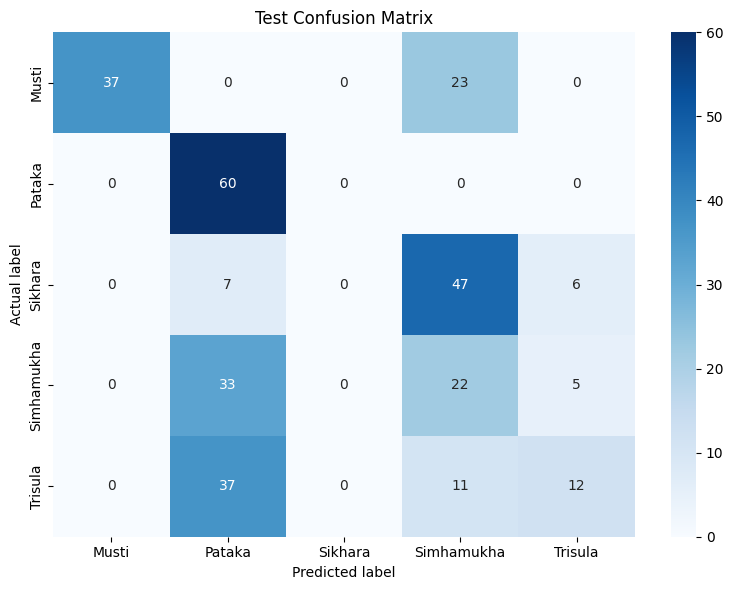

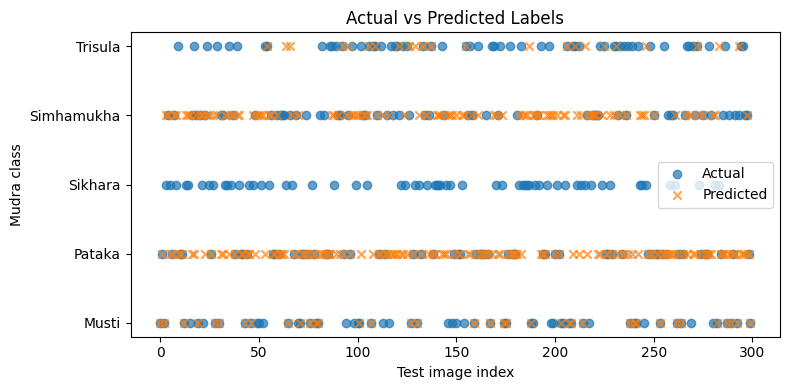

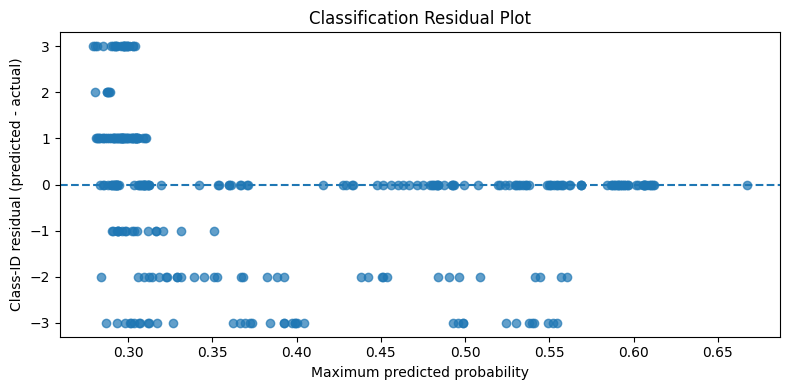

Misclassified: 169 / 300


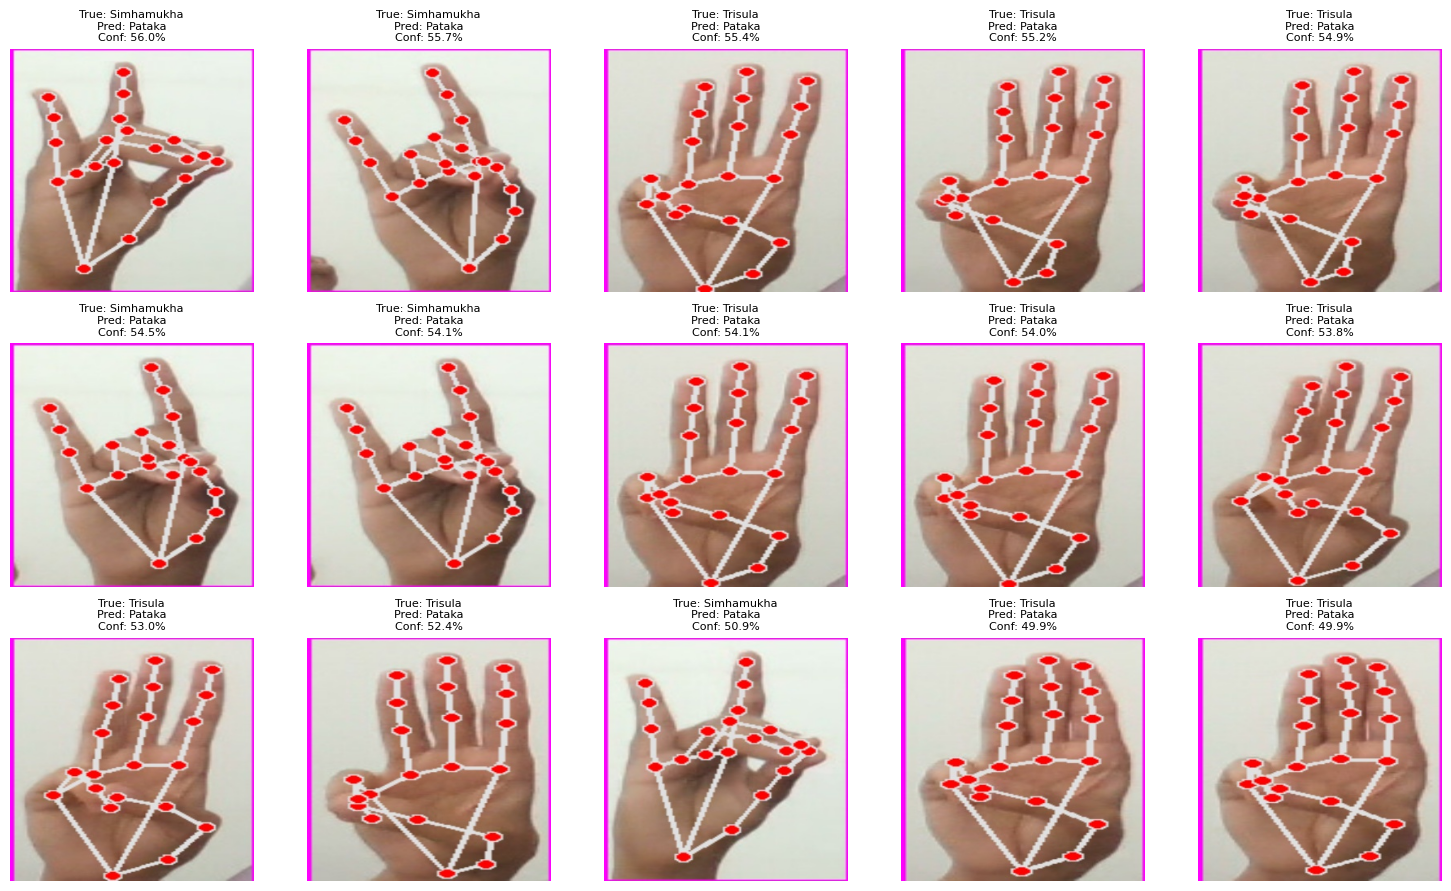

,image_path,actual,predicted,incorrect_prediction_confidence
157,/content/mudra_dataset/Bharatanatyam_Mudras/Si...,Simhamukha,Pataka,0.560134
39,/content/mudra_dataset/Bharatanatyam_Mudras/Si...,Simhamukha,Pataka,0.556624
31,/content/mudra_dataset/Bharatanatyam_Mudras/Tr...,Trisula,Pataka,0.554410
136,/content/mudra_dataset/Bharatanatyam_Mudras/Tr...,Trisula,Pataka,0.551911
162,/content/mudra_dataset/Bharatanatyam_Mudras/Tr...,Trisula,Pataka,0.549420
77,/content/mudra_dataset/Bharatanatyam_Mudras/Si...,Simhamukha,Pataka,0.544585
43,/content/mudra_dataset/Bharatanatyam_Mudras/Si...,Simhamukha,Pataka,0.541261
137,/content/mudra_dataset/Bharatanatyam_Mudras/Tr...,Trisula,Pataka,0.540838
166,/content/mudra_dataset/Bharatanatyam_Mudras/Tr...,Trisula,Pataka,0.539800
70,/content/mudra_dataset/Bharatanatyam_Mudras/Tr...,Trisula,Pataka,0.538046


Most confused direction: Sikhara predicted as Simhamukha | count: 47
Incorrect-prediction confidence mean: 0.3408
Correct-prediction confidence mean: 0.4626


In [17]:

import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)

os.makedirs("screenshots", exist_ok=True)

def collect_predictions(model, frame):
    ds = make_dataset(frame, training=False)
    probs = model.predict(ds, verbose=0)
    y_true = frame["label_id"].to_numpy()
    y_pred = probs.argmax(axis=1)
    confidence = probs.max(axis=1)
    return y_true, y_pred, probs, confidence

# Predictions and metrics
y_true, y_pred, y_prob, confidence = collect_predictions(
    custom_model, test_df
)

metrics = {
    "Accuracy": accuracy_score(y_true, y_pred),
    "Precision (macro)": precision_score(
        y_true, y_pred, average="macro", zero_division=0
    ),
    "Recall (macro)": recall_score(
        y_true, y_pred, average="macro", zero_division=0
    ),
    "F1-score (macro)": f1_score(
        y_true, y_pred, average="macro", zero_division=0
    ),
}

display(pd.DataFrame({
    "Metric": metrics.keys(),
    "Score": [round(v, 4) for v in metrics.values()]
}))

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=labels,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=labels, yticklabels=labels
)
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("Test Confusion Matrix")
plt.tight_layout()
plt.savefig("screenshots/confusion_matrix.png", dpi=150,
            bbox_inches="tight")
plt.show()

# Actual vs predicted
plt.figure(figsize=(8, 4))
plt.scatter(np.arange(len(y_true)), y_true, label="Actual", alpha=0.7)
plt.scatter(np.arange(len(y_pred)), y_pred, label="Predicted",
            alpha=0.7, marker="x")
plt.yticks(range(NUM_CLASSES), labels)
plt.xlabel("Test image index")
plt.ylabel("Mudra class")
plt.title("Actual vs Predicted Labels")
plt.legend()
plt.tight_layout()
plt.savefig("screenshots/actual_vs_predicted.png", dpi=150,
            bbox_inches="tight")
plt.show()

# Classification residual plot
residuals = y_pred - y_true

plt.figure(figsize=(8, 4))
plt.scatter(confidence, residuals, alpha=0.7)
plt.axhline(0, linestyle="--")
plt.xlabel("Maximum predicted probability")
plt.ylabel("Class-ID residual (predicted - actual)")
plt.title("Classification Residual Plot")
plt.tight_layout()
plt.savefig("screenshots/residual_plot.png", dpi=150,
            bbox_inches="tight")
plt.show()

# Error analysis
mis_idx = np.where(y_pred != y_true)[0]
correct_idx = np.where(y_pred == y_true)[0]

print(f"Misclassified: {len(mis_idx)} / {len(y_true)}")

if len(mis_idx) == 0:
    print("No misclassified test images were found.")
else:
    chosen = sorted(
        mis_idx, key=lambda i: confidence[i], reverse=True
    )[:15]

    rows = math.ceil(len(chosen) / 5)
    plt.figure(figsize=(15, max(5, rows * 3)))

    for plot_i, i in enumerate(chosen, 1):
        row = test_df.iloc[i]
        img = Image.open(row["path"]).convert("RGB")

        plt.subplot(rows, 5, plot_i)
        plt.imshow(img)
        plt.title(
            f"True: {id_to_label[int(y_true[i])]}\n"
            f"Pred: {id_to_label[int(y_pred[i])]}\n"
            f"Conf: {confidence[i]:.1%}",
            fontsize=8
        )
        plt.axis("off")

    plt.tight_layout()
    plt.savefig("screenshots/misclassified_images.png", dpi=150,
                bbox_inches="tight")
    plt.show()

    error_table = pd.DataFrame({
        "image_path": test_df.iloc[mis_idx]["path"].values,
        "actual": [id_to_label[int(y_true[i])] for i in mis_idx],
        "predicted": [id_to_label[int(y_pred[i])] for i in mis_idx],
        "incorrect_prediction_confidence": [
            float(confidence[i]) for i in mis_idx
        ]
    }).sort_values(
        "incorrect_prediction_confidence", ascending=False
    )

    display(error_table.head(30))
    error_table.to_csv("misclassified_predictions.csv", index=False)

# Most-confused class pair
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)

if cm_off.max() > 0:
    pair = np.unravel_index(np.argmax(cm_off), cm_off.shape)
    print(
        "Most confused direction:", labels[pair[0]],
        "predicted as", labels[pair[1]],
        "| count:", int(cm_off[pair])
    )
else:
    print("No off-diagonal confusion in the test confusion matrix.")

# Confidence comparison
if len(mis_idx):
    print(
        "Incorrect-prediction confidence mean:",
        round(float(confidence[mis_idx].mean()), 4)
    )

if len(correct_idx):
    print(
        "Correct-prediction confidence mean:",
        round(float(confidence[correct_idx].mean()), 4)
    )


### Analytical answers — Task 4
1. **Most confused pair:** The most frequently confused pair is Sikhara and Simhamukha, with 47 Sikhara samples misclassified as Simhamukha. Their hand shapes may share similar finger positions or orientations, making them difficult for the CNN to distinguish.
2. **Confidence on errors:** The misclassified samples have an average confidence of 34.08%, compared with 46.26% for correctly classified samples. Thus, incorrect predictions are generally lower-confidence, indicating that the model struggles to identify distinguishing features between similar Mudras. However, some incorrect predictions have confidence above 50%, showing that the model can also make confident mistakes.
3. **Improvements:** Data-centric improvement: Add more diverse, clearly labelled images of confusing Mudra classes, with variations in hand orientation, lighting, and background.
Model-centric improvement: Use transfer learning with a pretrained CNN such as MobileNetV2 to extract more effective visual features and improve classification performance.

## Bonus — Transfer learning with MobileNetV2



In [18]:
def build_mobilenet():
    inputs = keras.Input(shape=(*IMG_SIZE, 3))
    x = augmentation(inputs)
    x = layers.Lambda(lambda z: z * 2.0 - 1.0, name="mobilenet_preprocess")(x)
    base = keras.applications.MobileNetV2(input_shape=(*IMG_SIZE, 3), include_top=False,
                                          weights="imagenet")
    base.trainable = False
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.30)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    model = keras.Model(inputs, outputs, name="mobilenetv2_mudra")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

transfer_model = build_mobilenet()
callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
             keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2)]
t0 = time.time()
transfer_history = transfer_model.fit(train_ds, validation_data=val_ds, epochs=10,
                                      callbacks=callbacks, class_weight=class_weight, verbose=1)
transfer_train_seconds = time.time() - t0

# Evaluate both models
transfer_y, transfer_pred, transfer_prob, transfer_conf = collect_predictions(transfer_model, test_df)
transfer_acc = accuracy_score(transfer_y, transfer_pred)

def model_size_mb(model, path):
    model.save(path)
    return os.path.getsize(path) / (1024 * 1024)

custom_size_mb = model_size_mb(custom_model, "/content/custom_mudra_cnn.keras")
transfer_size_mb = model_size_mb(transfer_model, "/content/mobilenetv2_mudra.keras")

# Approximate batch-1 inference time, after warm-up.
def benchmark_inference(model, frame, n=50):
    sample_paths = frame["path"].astype(str).tolist()[:min(n, len(frame))]
    batch = []
    for p in sample_paths:
        with Image.open(p) as im:
            arr = np.asarray(im.convert("RGB").resize((IMG_SIZE[1], IMG_SIZE[0])), dtype=np.float32) / 255.0
        batch.append(arr)
    if not batch:
        return float("nan")
    x = np.stack(batch)
    model.predict(x[:1], verbose=0)  # warm-up
    start = time.time()
    model.predict(x, verbose=0)
    return (time.time()-start) / len(x) * 1000

custom_ms = benchmark_inference(custom_model, test_df)
transfer_ms = benchmark_inference(transfer_model, test_df)
comparison = pd.DataFrame([
    {"Model":"Custom CNN", "Test accuracy":accuracy_score(y_true,y_pred), "Model size (MB)":custom_size_mb,
     "Training time (s)":custom_train_seconds, "Approx. inference (ms/image)":custom_ms},
    {"Model":"MobileNetV2", "Test accuracy":transfer_acc, "Model size (MB)":transfer_size_mb,
     "Training time (s)":transfer_train_seconds, "Approx. inference (ms/image)":transfer_ms},
])
display(comparison.round(4))
comparison.to_csv("model_comparison.csv", index=False)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 53s 909ms/step - accuracy: 0.6214 - loss: 0.9866 - val_accuracy: 0.9200 - val_loss: 0.3866 - learning_rate: 0.0010
Epoch 2/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 39s 876ms/step - accuracy: 0.9143 - loss: 0.2957 - val_accuracy: 0.9167 - val_loss: 0.2581 - learning_rate: 0.0010
Epoch 3/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 40s 901ms/step - accuracy: 0.9500 - loss: 0.1867 - val_accuracy: 0.9567 - val_loss: 0.1677 - learning_rate: 0.0010
Epoch 4/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 39s 895ms/step - accuracy: 0.9757 - loss: 0.1165 - val_accuracy: 0.9700 - val_loss: 0.1193 - learning_rate: 0.0010
Epoch 5/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 39s 879ms/step - accuracy: 0.9786 - loss: 0.0953 - val_accuracy: 0.9800 - val_loss: 0.0912 - learning_rate: 0.0010
Epoch 6/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 39s 877ms/step - accuracy: 0.9857 - loss: 0.0737 - val_accuracy: 0.9800 - val_loss: 0.0929 - learning_rate: 0.0010
Epoch 7/10
44/44 ━━━━━━━━━━━━━━━━

,Model,Test accuracy,Model size (MB),Training time (s),Approx. inference (ms/image)
0,Custom CNN,0.4367,0.3301,347.9261,13.8444
1,MobileNetV2,0.9967,9.2633,405.6836,52.1545


## Save deployment artefacts and screenshot folder

In [19]:

os.makedirs("screenshots", exist_ok=True)
custom_model.save("mudra_cnn.keras")
transfer_model.save("mobilenetv2_mudra.keras")
with open("class_names.json", "w", encoding="utf-8") as f:
    json.dump(labels, f, ensure_ascii=False, indent=2)


with open("evaluation_summary.json", "w", encoding="utf-8") as f:
    json.dump({
        "classes": labels,
        "test_metrics": {k: float(v) for k, v in metrics.items()},
        "custom_cnn_size_mb": float(custom_size_mb),
        "mobilenetv2_size_mb": float(transfer_size_mb),
        "custom_cnn_training_seconds": float(custom_train_seconds),
        "mobilenetv2_training_seconds": float(transfer_train_seconds),
        "custom_cnn_inference_ms_per_image": float(custom_ms),
        "mobilenetv2_inference_ms_per_image": float(transfer_ms)
    }, f, indent=2)
print("Saved models, labels, metrics and screenshots.")

Saved models, labels, metrics and screenshots.


## Task 5 — Streamlit deployment

The app below is generated as `app.py`. It includes Home, Predict, and About pages. The prediction page shows the top class, confidence, and probabilities for every class. Confidence is useful for transparency, but users should treat low-confidence outputs as uncertain and follow instructor guidance.

In [21]:
app_source = r'''
import json
from pathlib import Path
import numpy as np
import streamlit as st
from PIL import Image
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt

st.set_page_config(page_title="Bharatanatyam Mudra AI", page_icon="🪷", layout="centered")
BASE_DIR = Path(__file__).resolve().parent
MODEL_PATH = BASE_DIR / "mudra_cnn.keras"
LABELS_PATH = BASE_DIR / "class_names.json"
IMG_SIZE = (160, 160)

@st.cache_resource
def load_artifacts():
    model = tf.keras.models.load_model(MODEL_PATH)
    with open(LABELS_PATH, "r", encoding="utf-8") as f:
        labels = json.load(f)
    return model, labels

def preprocess(image):
    image = image.convert("RGB").resize((IMG_SIZE[1], IMG_SIZE[0]))
    arr = np.asarray(image, dtype=np.float32) / 255.0
    return np.expand_dims(arr, axis=0)

st.sidebar.title("🪷 Mudra Recognition")
page = st.sidebar.radio("Navigate", ["Home", "Predict", "About"])

if page == "Home":
    st.title("Bharatanatyam Mudra Recognition")
    st.subheader("AI-assisted practice for classical dance learners")
    st.write("Upload a hand-mudra image to receive a model prediction and class probabilities.")
    st.info("This tool is a learning aid, not a replacement for guidance from a qualified Bharatanatyam teacher.")
    st.markdown("### How to use")
    st.markdown("1. Open **Predict**.\n2. Upload a clear image showing the hand gesture.\n3. Review the predicted class and confidence.\n4. If confidence is low, retake the photo with better lighting and a plain background.")
elif page == "Predict":
    st.title("Predict a Mudra")
    uploaded = st.file_uploader("Upload a hand-mudra image", type=["jpg", "jpeg", "png", "webp"])
    if uploaded:
        image = Image.open(uploaded).convert("RGB")
        st.image(image, caption="Uploaded image", use_container_width=True)
        with st.spinner("Analysing the image..."):
            model, labels = load_artifacts()
            probs = model.predict(preprocess(image), verbose=0)[0]
        idx = int(np.argmax(probs))
        st.success(f"Predicted mudra: **{labels[idx]}**")
        st.metric("Confidence", f"{probs[idx]:.1%}")
        chart_df = pd.DataFrame({"Mudra": labels, "Probability": probs}).sort_values("Probability", ascending=False)
        st.markdown("### Probability distribution")
        st.bar_chart(chart_df.set_index("Mudra"))
        st.dataframe(chart_df.assign(Probability=chart_df["Probability"].map(lambda x: f"{x:.2%}")),
                     use_container_width=True, hide_index=True)
        if probs[idx] < 0.60:
            st.warning("The model is uncertain about this image. Try a clearer photo or ask your instructor to verify the mudra.")
elif page == "About":
    st.title("About this project")
    st.write("This application classifies images into five Bharatanatyam mudra categories represented in the training dataset.")
    st.write("Model: custom convolutional neural network (CNN). Input: RGB image resized to 160 × 160 pixels and scaled to [0, 1].")
    st.write("Evaluation should be reported using the held-out test set, macro precision/recall/F1, a confusion matrix, and error analysis.")
    st.warning("Predictions depend on the dataset and image conditions. The model may be wrong, especially for unfamiliar backgrounds, angles, or similar gestures.")
'''
with open("app.py", "w", encoding="utf-8") as f:
    f.write(app_source)

In [22]:
requirements = '''tensorflow>=2.15
streamlit>=1.32
numpy
pandas
Pillow
matplotlib
scikit-learn
seaborn
'''
with open("requirements.txt", "w", encoding="utf-8") as f:
    f.write(requirements)

readme = '''# Bharatanatyam Mudra Recognition

Image classification project for recognizing five Bharatanatyam mudra classes using a custom CNN, with MobileNetV2 transfer learning comparison and a Streamlit interface.

## Repository contents
- `Bharatanatyam_Mudra_Recognition.ipynb` — end-to-end Colab notebook (EDA, splits, augmentation, training, evaluation, error analysis, transfer learning).
- `app.py` — Streamlit app (Home, Predict, About).
- `mudra_cnn.keras` — trained custom CNN (generated after running the notebook).
- `mobilenetv2_mudra.keras` — transfer-learning model (generated after running the notebook).
- `class_names.json` — model class labels.
- `screenshots/` — dataset preview, EDA, training curves, confusion matrix, errors, and app screenshots (generated during execution).
- `requirements.txt` — Python dependencies.

## Run in Google Colab
1. Open the notebook in Colab.
2. Upload `mudra.zip` when prompted.
3. Select a GPU runtime if available.
4. Run all cells from top to bottom.
5. Download the generated models, `app.py`, `requirements.txt`, `class_names.json`, metrics CSV/JSON, and `screenshots/`.

## Run Streamlit locally
Use Python 3.10–3.11 for broad TensorFlow compatibility. From the repository directory:
```bash
python -m venv .venv
# Windows: .venv\\Scripts\\activate
# macOS/Linux: source .venv/bin/activate
pip install -r requirements.txt
streamlit run app.py
```
Keep `mudra_cnn.keras` and `class_names.json` in the same directory as `app.py`.

## Dataset
The dataset ZIP is not included in this public repository unless you have permission to redistribute it. The notebook extracts the ZIP and infers class names from folder names. Check the detected class list before training.

## Reporting
Report metrics and interpretations produced by your own run. Do not report placeholder or fabricated scores. For classification, the residual plot is an illustrative class-ID residual plot; regression-specific residual analysis is not applicable.
'''
with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme)

print("Generated app.py, requirements.txt and README.md")

Generated app.py, requirements.txt and README.md


## Final analytical answers — Task 5
1. **Why show confidence?** It helps learners judge how certain the model is and encourages them to retake an unclear image or seek instructor verification when the result is uncertain. Confidence is not a calibrated probability of correctness unless calibration is tested.
2. **Useful additional feature:** add a short reference image/video and step-by-step finger-position guidance for the predicted mudra, ideally reviewed by a Bharatanatyam instructor. A practice history could also help learners track improvement.

In [23]:
import zipfile, os
from pathlib import Path
artifact_names = [
    "app.py", "requirements.txt", "README.md", "mudra_cnn.keras",
    "mobilenetv2_mudra.keras", "class_names.json", "evaluation_summary.json",
    "model_comparison.csv", "misclassified_predictions.csv"
]
package_path = Path("/content/mudra_colab_project.zip")
with zipfile.ZipFile(package_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for name in artifact_names:
        p = Path("/content") / name
        if p.exists():
            zf.write(p, arcname=name)
    shot_dir = Path("/content/screenshots")
    if shot_dir.exists():
        for p in shot_dir.rglob("*"):
            if p.is_file():
                zf.write(p, arcname=f"screenshots/{p.relative_to(shot_dir)}")
print("Package created:", package_path)
try:
    from google.colab import files
    files.download(str(package_path))
except Exception as e:
    print("Download manually from the Files pane:", e)

Package created: /content/mudra_colab_project.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
custom_model.save("mudra_model.keras")

In [26]:

%%writefile app.py
import streamlit as st
import numpy as np
import tensorflow as tf
import json
from PIL import Image

st.set_page_config(
    page_title="Mudra Recognition",
    page_icon="🙏",
    layout="centered"
)

@st.cache_resource
def load_model():
    return tf.keras.models.load_model("mudra_model.keras")

@st.cache_data
def load_labels():
    with open("labels.json", "r") as f:
        return json.load(f)

model = load_model()
LABELS = load_labels()

# Match the image size used during training
IMG_SIZE = (128, 128)

st.title("🙏 Mudra Recognition")
st.write(
    "Upload a Bharatanatyam hand gesture image "
    "to predict its Mudra class."
)

uploaded_file = st.file_uploader(
    "Upload a hand gesture image",
    type=["jpg", "jpeg", "png"]
)

if uploaded_file is not None:
    try:
        image = Image.open(uploaded_file).convert("RGB")
        st.image(image, caption="Uploaded image", width=300)

        resized = image.resize((IMG_SIZE[1], IMG_SIZE[0]))
        img_array = np.array(resized, dtype=np.float32)

        # Use this only if training images were rescaled to [0, 1].
        img_array = img_array / 255.0
        img_array = np.expand_dims(img_array, axis=0)

        if len(LABELS) != model.output_shape[-1]:
            st.error("The number of labels does not match the model.")
        else:
            probabilities = model.predict(img_array, verbose=0)[0]
            predicted_index = int(np.argmax(probabilities))

            st.success(
                f"Predicted Mudra: {LABELS[predicted_index]}"
            )
            st.metric(
                "Prediction confidence",
                f"{probabilities[predicted_index]:.2%}"
            )

            st.subheader("Class probabilities")
            for i, label in enumerate(LABELS):
                st.write(f"{label}: {probabilities[i]:.2%}")

    except Exception as e:
        st.error(f"Could not process this image: {e}")


Overwriting app.py


In [27]:
import json

with open("labels.json", "w") as f:
    json.dump(
        [str(id_to_label[i]) for i in range(NUM_CLASSES)],
        f,
        indent=4
    )

print("Saved labels:", [id_to_label[i] for i in range(NUM_CLASSES)])

Saved labels: ['Musti', 'Pataka', 'Sikhara', 'Simhamukha', 'Trisula']
